### Installing libraries

In [ ]:
import json
import subprocess
import sys
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import xgboost

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve
)
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RandomizedSearchCV,
    cross_validate,
    cross_val_predict
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler

from xgboost import XGBClassifier

In [ ]:
ROOT = Path('..') if Path('../src').exists() else Path('.')
DATA_PATH = ROOT / 'data' / 'WE_Churn_Modeling_Dataset.csv'
df = pd.read_csv(DATA_PATH)

print("=== Dataset Shape ===")
print(df.shape)

print("\n=== Info & Data Types ===")
df.info()

print("\n=== Missing Values ===")
print(df.isnull().sum())


df.head()

=== Dataset Shape ===
(9205, 10)

=== Info & Data Types ===
<class 'pandas.DataFrame'>
RangeIndex: 9205 entries, 0 to 9204
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             9205 non-null   str    
 1   governorate             9186 non-null   str    
 2   customer_type           9193 non-null   str    
 3   subscription_plan       9199 non-null   str    
 4   monthly_bill_egp        9179 non-null   float64
 5   payment_method          9170 non-null   str    
 6   tenure_months           9174 non-null   float64
 7   complaint_count         9182 non-null   float64
 8   downtime_hours_monthly  9163 non-null   float64
 9   churned                 9205 non-null   int64  
dtypes: float64(4), int64(1), str(5)
memory usage: 719.3 KB

=== Missing Values ===
customer_id                0
governorate               19
customer_type             12
subscription_plan          6
monthly_

,customer_id,governorate,customer_type,subscription_plan,monthly_bill_egp,payment_method,tenure_months,complaint_count,downtime_hours_monthly,churned
0,TE003208,Cairo,Individual,WE Standard 20Mbps,300.83,Vodafone Cash,35.0,0.0,5.8,0
1,TE004897,Alexandria,Individual,WE Ultra 200Mbps,849.37,Vodafone Cash,23.0,0.0,NaN,0
2,TE005889,Sharqia,Business,WE Ultra 200Mbps,815.13,Direct Debit,77.0,0.0,1.9,0
3,TE001725,Beheira,Individual,WE Plus 40Mbps,399.26,Credit Card,26.0,0.0,1.8,0
4,TE000510,Beni Suef,Individual,WE Standard 20Mbps,318.57,Vodafone Cash,78.0,0.0,3.2,0


In [6]:
print(f"Number of duplicate rows: {df.duplicated().sum()}")

Number of duplicate rows: 142


In [7]:
df.drop_duplicates(inplace=True)

### 1. Most Popular Payment Method (Countplot)

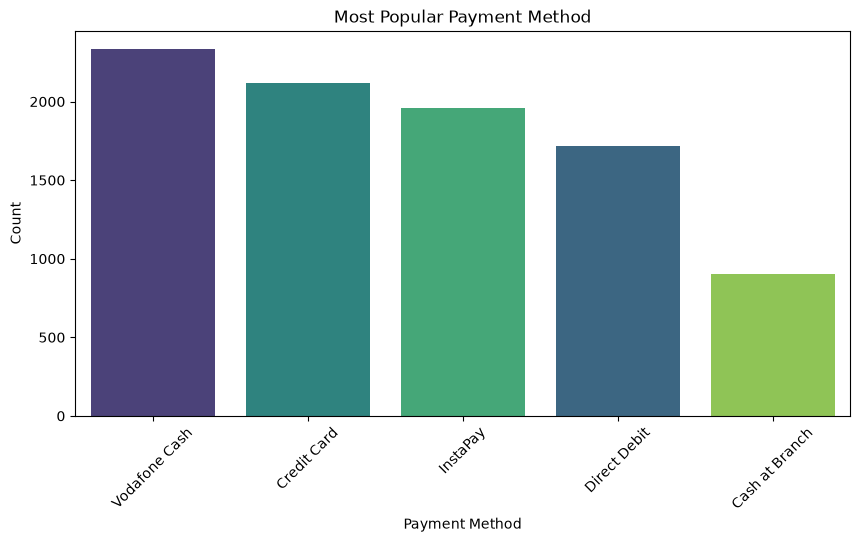

In [8]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='payment_method', hue='payment_method', palette='viridis', legend=False, order=df['payment_method'].value_counts().index)
plt.title('Most Popular Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

### 2. Most Popular Subscription Plan (Countplot)

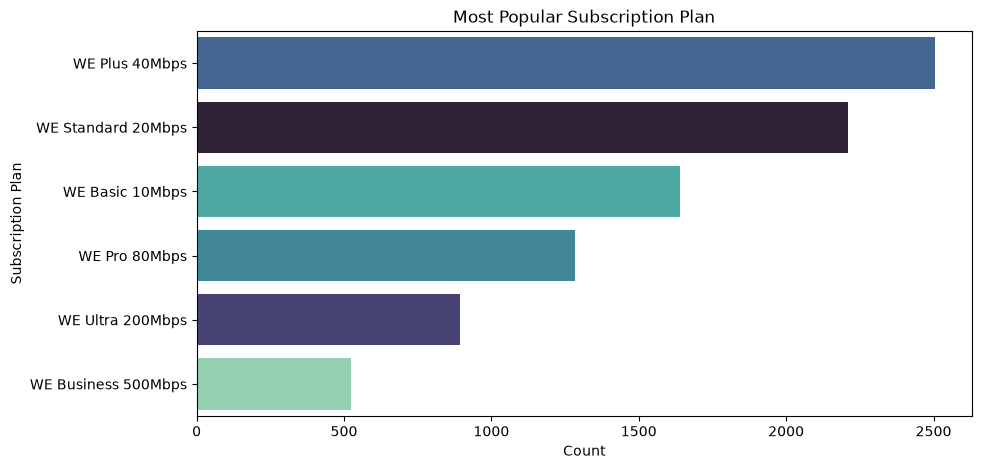

In [9]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, y='subscription_plan', hue='subscription_plan', palette='mako', legend=False, order=df['subscription_plan'].value_counts().index)
plt.title('Most Popular Subscription Plan')
plt.xlabel('Count')
plt.ylabel('Subscription Plan')
plt.show()

### 3. Governorates with the Most Customers (Bar Chart)

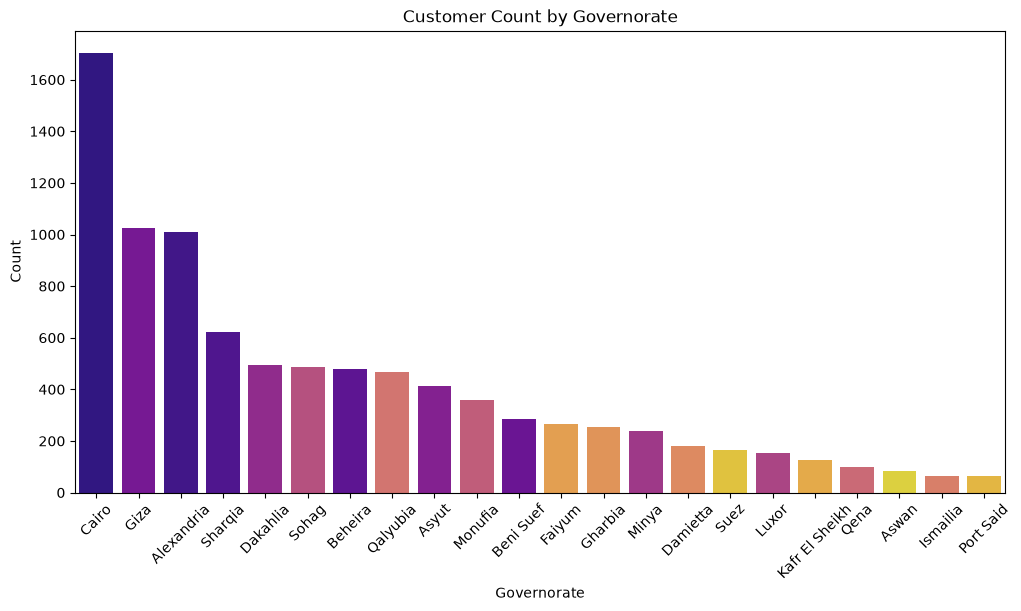

In [10]:
plt.figure(figsize=(12, 6))
sns.countplot(data=df, x='governorate', hue='governorate', palette='plasma', legend=False, order=df['governorate'].value_counts().index)
plt.title('Customer Count by Governorate')
plt.xlabel('Governorate')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

### 4. Most Common Customer Type (Bar Chart)

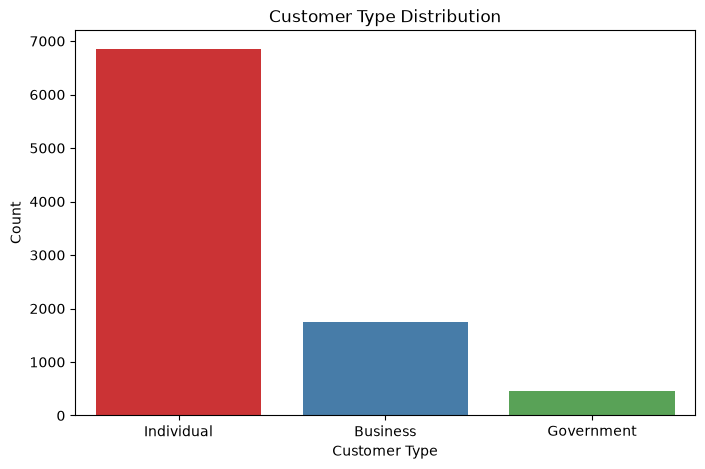

In [11]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='customer_type', hue='customer_type', palette='Set1', legend=False)
plt.title('Customer Type Distribution')
plt.xlabel('Customer Type')
plt.ylabel('Count')
plt.show()

### 5. Distribution of Customer Complaints (Histogram)

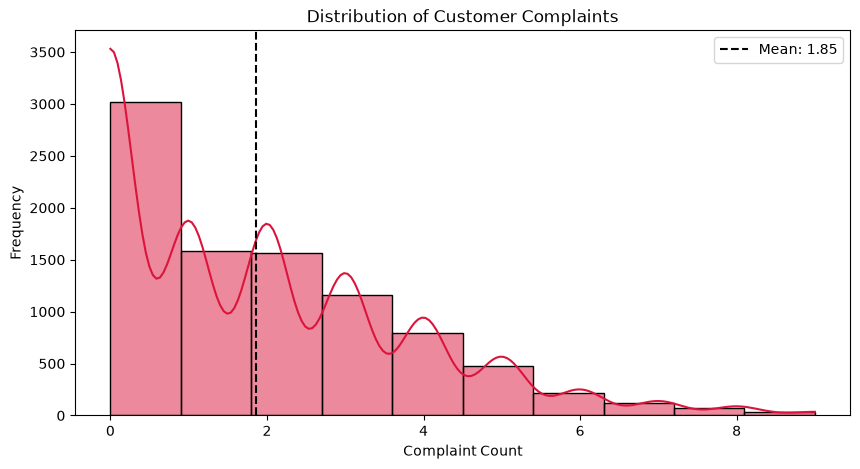

In [12]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='complaint_count', kde=True, bins=10, color='crimson')
plt.axvline(df['complaint_count'].mean(), color='black', linestyle='--', label=f'Mean: {df["complaint_count"].mean():.2f}')
plt.title('Distribution of Customer Complaints')
plt.xlabel('Complaint Count')
plt.ylabel('Frequency')
plt.legend()
plt.show()

### 6. Average Monthly Downtime Hours (Histogram)

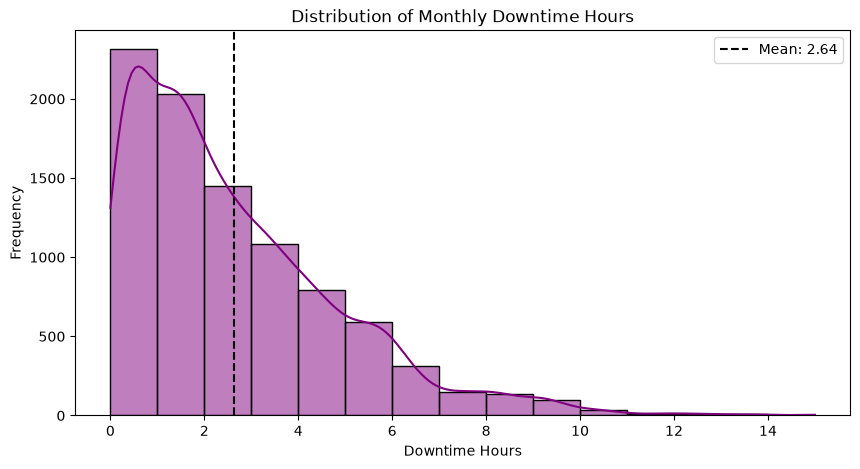

In [13]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='downtime_hours_monthly', kde=True, bins=15, color='purple')
plt.axvline(df['downtime_hours_monthly'].mean(), color='black', linestyle='--', label=f'Mean: {df["downtime_hours_monthly"].mean():.2f}')
plt.title('Distribution of Monthly Downtime Hours')
plt.xlabel('Downtime Hours')
plt.ylabel('Frequency')
plt.legend()
plt.show()

### 7. Distribution of Customer Tenure (Histogram)

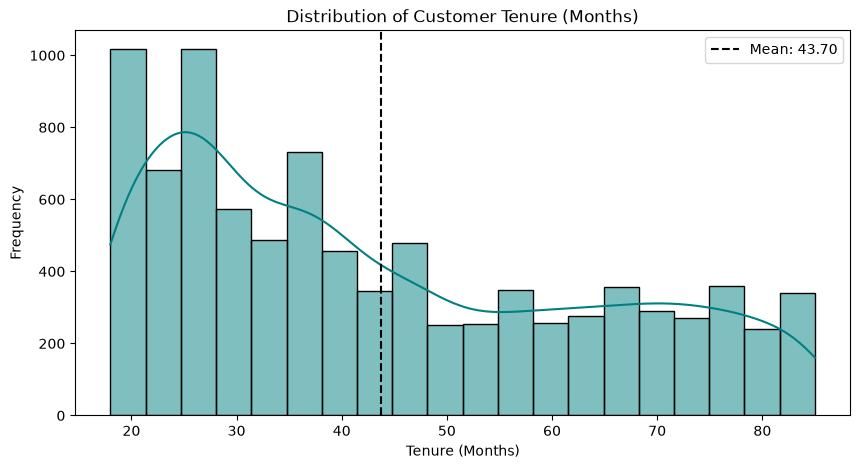

In [14]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='tenure_months', kde=True, bins=20, color='teal')
plt.axvline(df['tenure_months'].mean(), color='black', linestyle='--', label=f'Mean: {df["tenure_months"].mean():.2f}')
plt.title('Distribution of Customer Tenure (Months)')
plt.xlabel('Tenure (Months)')
plt.ylabel('Frequency')
plt.legend()
plt.show()

### 8. Churn Rate by Subscription Plan (Bar Chart)

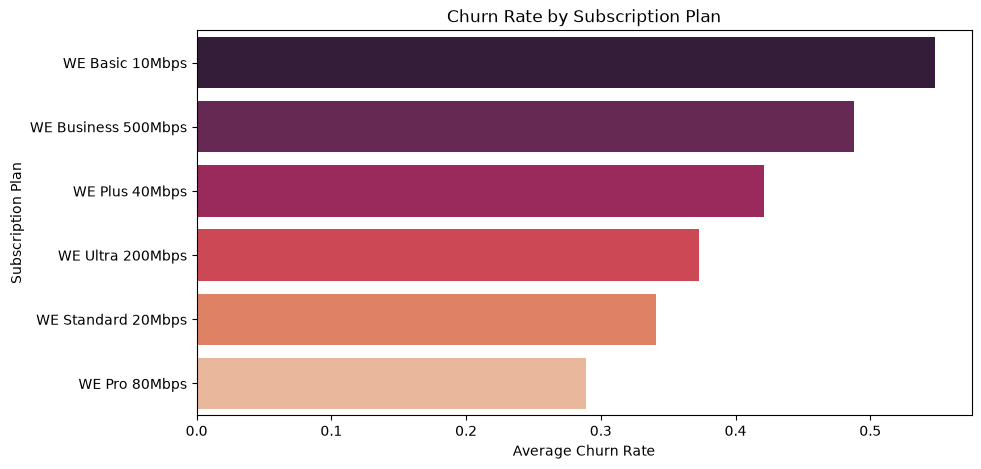

In [15]:
plan_churn_rate = df.groupby('subscription_plan')['churned'].mean().reset_index().sort_values(by='churned', ascending=False)
plt.figure(figsize=(10, 5))
sns.barplot(data=plan_churn_rate, x='churned', y='subscription_plan', hue='subscription_plan', palette='rocket', legend=False)
plt.title('Churn Rate by Subscription Plan')
plt.xlabel('Average Churn Rate')
plt.ylabel('Subscription Plan')
plt.show()

### 9. Churn Rate by Payment Method (Bar Chart)

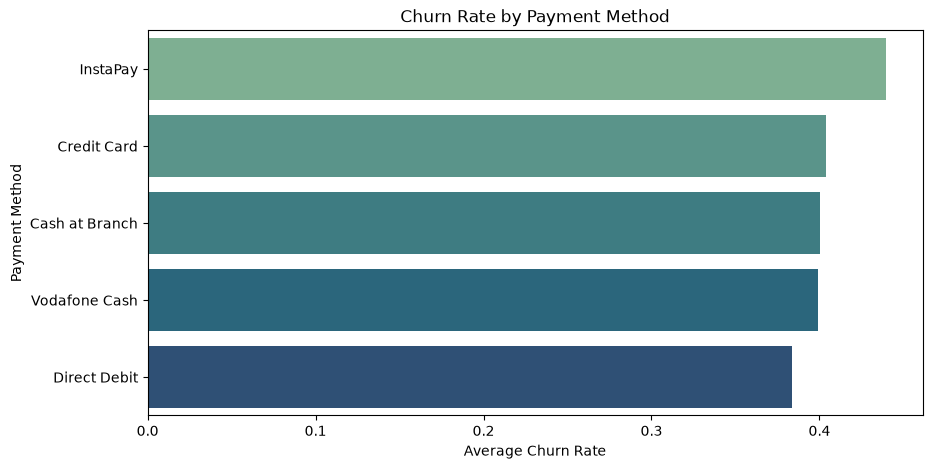

In [16]:
payment_churn_rate = df.groupby('payment_method')['churned'].mean().reset_index().sort_values(by='churned', ascending=False)
plt.figure(figsize=(10, 5))
sns.barplot(data=payment_churn_rate, x='churned', y='payment_method', hue='payment_method', palette='crest', legend=False)
plt.title('Churn Rate by Payment Method')
plt.xlabel('Average Churn Rate')
plt.ylabel('Payment Method')
plt.show()

=== Churn Rate by Complaint Count ===
 complaint_count  churn_rate  customer_count
             0.0    0.036828            3014
             1.0    0.065698            1583
             2.0    0.620932            1567
             3.0    0.798623            1162
             4.0    0.876095             799
             5.0    0.887500             480
             6.0    0.976415             212
             7.0    0.957627             118
             8.0    1.000000              75
             9.0    1.000000              30


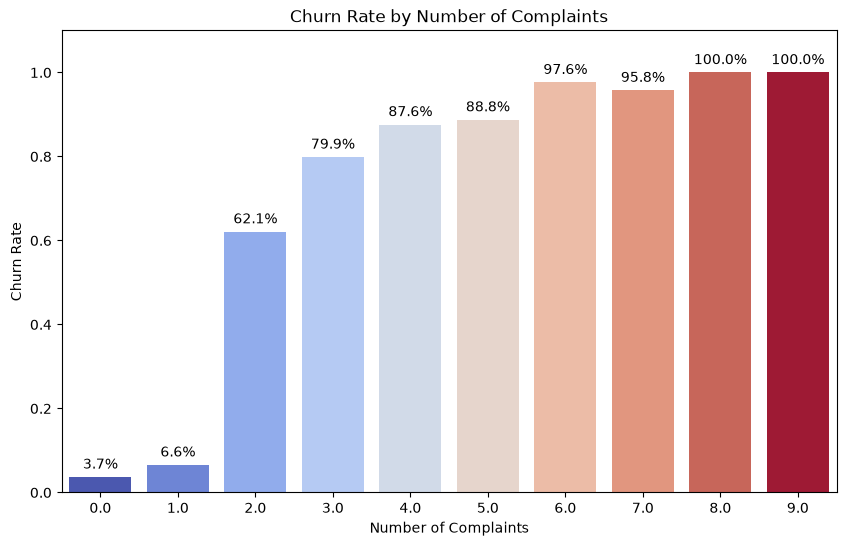

In [ ]:
complaint_churn = df.groupby('complaint_count')['churned'].agg(['mean', 'count']).reset_index()
complaint_churn.rename(columns={'mean': 'churn_rate', 'count': 'customer_count'}, inplace=True)

print("=== Churn Rate by Complaint Count ===")
print(complaint_churn.to_string(index=False))

plt.figure(figsize=(10, 6))
sns.barplot(data=complaint_churn, x='complaint_count', y='churn_rate', hue='complaint_count', palette='coolwarm', legend=False)
plt.title('Churn Rate by Number of Complaints')
plt.xlabel('Number of Complaints')
plt.ylabel('Churn Rate')
plt.ylim(0, 1.1)

for index, row in complaint_churn.iterrows():
    plt.text(x=row['complaint_count'], y=row['churn_rate'] + 0.02,
             s=f"{row['churn_rate']*100:.1f}%", color='black', ha="center", fontsize=10)

plt.show()

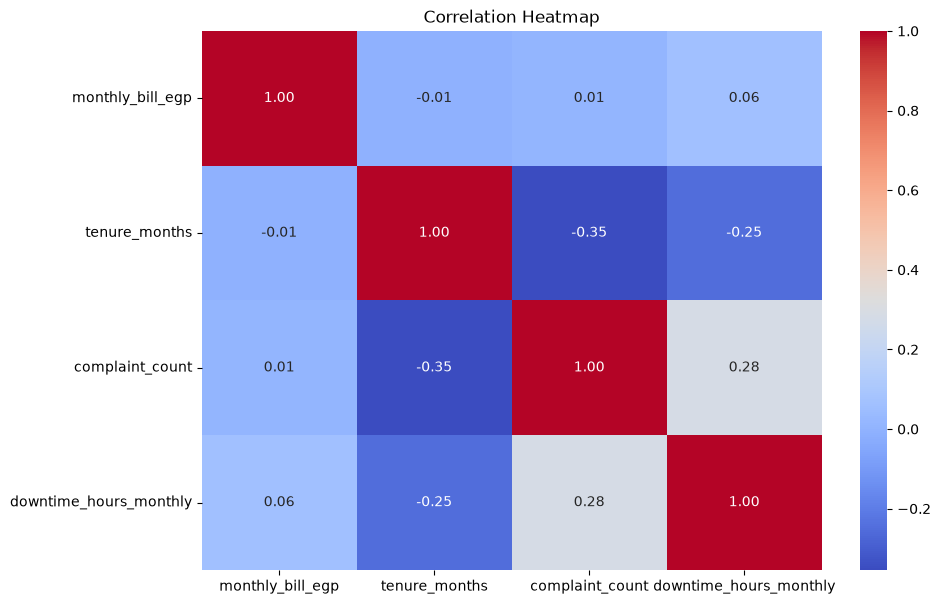

In [18]:
num_cols = [
    'monthly_bill_egp',
    'tenure_months',
    'complaint_count',
    'downtime_hours_monthly'
]
corr = df[num_cols].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

In [19]:
print("=== Outlier Counts (IQR Method) ===")
for col in num_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    percentage = (len(outliers) / len(df)) * 100
    print(f"{col}: {len(outliers)} outliers found ({percentage:.2f}% of total data)")

=== Outlier Counts (IQR Method) ===
monthly_bill_egp: 543 outliers found (5.99% of total data)
tenure_months: 0 outliers found (0.00% of total data)
complaint_count: 105 outliers found (1.16% of total data)
downtime_hours_monthly: 267 outliers found (2.95% of total data)


In [ ]:
cat_cols = [
    'governorate',
    'customer_type',
    'subscription_plan',
    'payment_method'
]

In [ ]:
print("=== Unique Value Counts for Categorical Columns ===")
for col in cat_cols:
    unique_vals = df[col].nunique()
    print(f"{col}: {unique_vals} unique values")

print("\nBased on this low cardinality and nominal nature, One-Hot Encoding is the most suitable method.")

=== Unique Value Counts for Categorical Columns ===
governorate: 22 unique values
customer_type: 3 unique values
subscription_plan: 6 unique values
payment_method: 5 unique values

Based on this low cardinality and nominal nature, One-Hot Encoding is the most suitable method.


In [23]:
# Remove all rows belonging to duplicated customer IDs
df = df.drop_duplicates(subset='customer_id', keep=False)

# Verify uniqueness
assert df['customer_id'].is_unique

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (8987, 10)


In [ ]:
TARGET = 'churned'
FEATURES = num_cols + cat_cols
SEED = 42

X = df[FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)
print(f'Train: {X_train.shape}  Test: {X_test.shape}  Churn rate (train): {y_train.mean():.3f}')

Train: (7189, 8)  Test: (1798, 8)  Churn rate (train): 0.408


In [ ]:
def build_pipeline(model, scale=False):
    num_steps = [('imp', SimpleImputer(strategy='median'))]
    if scale:  # only scale-sensitive models (logistic regression) need scaling; trees do not
        num_steps.append(('scale', RobustScaler()))
    pre = ColumnTransformer([
        ('num', Pipeline(num_steps), num_cols),
        ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                          ('oh', OneHotEncoder(handle_unknown='ignore'))]), cat_cols),
    ])
    return Pipeline([('pre', pre), ('model', model)])

In [ ]:
# [NEW] Helper functions for metrics, threshold choice and JSON saving
def metrics_at(y_true, proba, threshold):
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {
        'roc_auc': roc_auc_score(y_true, proba), 'pr_auc': average_precision_score(y_true, proba),
        'accuracy': accuracy_score(y_true, pred), 'precision': precision_score(y_true, pred, zero_division=0),
        'recall': recall_score(y_true, pred), 'f1': f1_score(y_true, pred),
        'confusion_matrix': [[int(tn), int(fp)], [int(fn), int(tp)]],
    }

def best_f1_threshold(y_true, proba):
    p, r, t = precision_recall_curve(y_true, proba)
    f1 = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-12, None)
    return float(t[int(np.nanargmax(f1))])

def to_native(o):  
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, np.floating): return float(o)
    if isinstance(o, np.ndarray): return o.tolist()
    raise TypeError(f'not JSON serialisable: {type(o)}')

### Compare baselines and models with stratified 5-fold CV (training set only)

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = {'roc_auc': 'roc_auc', 'pr_auc': 'average_precision', 'recall': 'recall', 'f1': 'f1', 'accuracy': 'accuracy'}

candidates = {
    'Dummy (most frequent)': build_pipeline(DummyClassifier(strategy='prior')),
    'Logistic Regression':   build_pipeline(LogisticRegression(max_iter=2000, class_weight='balanced'), scale=True),
    'Random Forest':         build_pipeline(RandomForestClassifier(n_estimators=300, class_weight='balanced',
                                                                   random_state=SEED, n_jobs=1)),
    'XGBoost':               build_pipeline(XGBClassifier(eval_metric='logloss', random_state=SEED, n_jobs=1)),
}

cv_results = {}
for name, pipe in candidates.items():
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=SCORING, n_jobs=-1)
    cv_results[name] = {m: {'mean': float(r[f'test_{m}'].mean()), 'std': float(r[f'test_{m}'].std())} for m in SCORING}

cv_table = pd.DataFrame({n: {m: f"{v[m]['mean']:.3f} +/- {v[m]['std']:.3f}" for m in SCORING}
                         for n, v in cv_results.items()}).T
print(cv_table.to_string())

                               roc_auc           pr_auc           recall               f1         accuracy
Dummy (most frequent)  0.500 +/- 0.000  0.408 +/- 0.000  0.000 +/- 0.000  0.000 +/- 0.000  0.592 +/- 0.000
Logistic Regression    0.989 +/- 0.001  0.983 +/- 0.002  0.957 +/- 0.009  0.941 +/- 0.003  0.951 +/- 0.002
Random Forest          0.992 +/- 0.001  0.990 +/- 0.001  0.938 +/- 0.012  0.948 +/- 0.008  0.958 +/- 0.006
XGBoost                0.992 +/- 0.000  0.989 +/- 0.001  0.953 +/- 0.007  0.949 +/- 0.004  0.958 +/- 0.004


### Tune with `RandomizedSearchCV` on the whole pipeline

In [28]:
# Faster hyperparameter tuning
N_ITER = 5

search_spaces = {
    'Random Forest': {
        'model__n_estimators': [100, 200],
        'model__max_depth': [6, 10, None],
        'model__min_samples_leaf': [1, 3, 5],
        'model__max_features': ['sqrt'],
        'model__class_weight': ['balanced', None],
    },

    'XGBoost': {
        'model__n_estimators': [100, 200],
        'model__max_depth': [3, 4, 5],
        'model__learning_rate': [0.05, 0.1, 0.2],
        'model__subsample': [0.8, 1.0],
        'model__colsample_bytree': [0.8, 1.0],
    },
}

searches = {}

for name, space in search_spaces.items():

    s = RandomizedSearchCV(
        candidates[name],
        space,
        n_iter=N_ITER,
        scoring='average_precision',
        cv=3,
        n_jobs=-1,
        random_state=SEED,
        refit=True
    )

    s.fit(X_train, y_train)
    searches[name] = s

    print(f'{name:<14} best CV PR-AUC = {s.best_score_:.4f}')
    print(f'               params = {s.best_params_}')

best_name = max(searches, key=lambda n: searches[n].best_score_)
best_search = searches[best_name]

print(f'\nChosen model: {best_name}')

Random Forest  best CV PR-AUC = 0.9897
               params = {'model__n_estimators': 200, 'model__min_samples_leaf': 1, 'model__max_features': 'sqrt', 'model__max_depth': None, 'model__class_weight': 'balanced'}
XGBoost        best CV PR-AUC = 0.9894
               params = {'model__subsample': 0.8, 'model__n_estimators': 200, 'model__max_depth': 4, 'model__learning_rate': 0.1, 'model__colsample_bytree': 0.8}

Chosen model: Random Forest


### Choose the decision threshold from CV predictions (not from the test set)

Threshold = 0.510  ->  CV recall = 0.937, precision = 0.958, F1 = 0.947


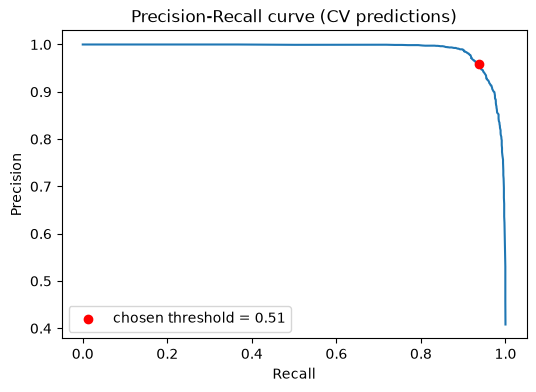

In [ ]:
oof_proba = cross_val_predict(clone(best_search.best_estimator_), X_train, y_train, cv=cv,
                              method='predict_proba', n_jobs=-1)[:, 1]
threshold = best_f1_threshold(y_train, oof_proba)
cv_at_threshold = metrics_at(y_train, oof_proba, threshold)
print(f'Threshold = {threshold:.3f}  ->  CV recall = {cv_at_threshold["recall"]:.3f}, '
      f'precision = {cv_at_threshold["precision"]:.3f}, F1 = {cv_at_threshold["f1"]:.3f}')

prec, rec, thr = precision_recall_curve(y_train, oof_proba)
plt.figure(figsize=(6, 4))
plt.plot(rec, prec)
plt.scatter([cv_at_threshold['recall']], [cv_at_threshold['precision']], color='red', zorder=3,
            label=f'chosen threshold = {threshold:.2f}')
plt.xlabel('Recall'); plt.ylabel('Precision'); plt.title('Precision-Recall curve (CV predictions)')
plt.legend(); plt.show()

### Final evaluation on the test set (used once)

Model: Random Forest   threshold: 0.510

              precision    recall  f1-score   support

    Retained       0.96      0.97      0.97      1065
     Churned       0.96      0.94      0.95       733

    accuracy                           0.96      1798
   macro avg       0.96      0.96      0.96      1798
weighted avg       0.96      0.96      0.96      1798

{'roc_auc': 0.9925, 'pr_auc': 0.9909, 'accuracy': 0.9616, 'precision': 0.9611, 'recall': 0.9441, 'f1': 0.9525}


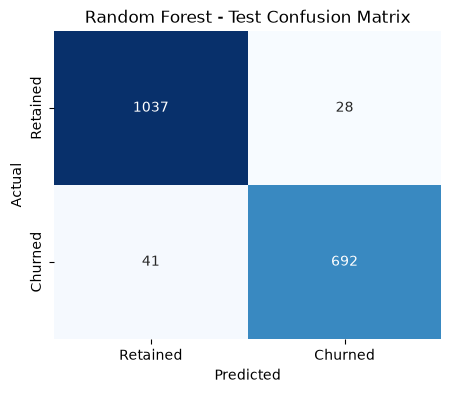

In [ ]:
final_model = best_search.best_estimator_
test_proba = final_model.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= threshold).astype(int)
test_metrics = metrics_at(y_test, test_proba, threshold)

print(f'Model: {best_name}   threshold: {threshold:.3f}\n')
print(classification_report(y_test, test_pred, target_names=['Retained', 'Churned']))
print({k: round(v, 4) for k, v in test_metrics.items() if k != 'confusion_matrix'})

cm = confusion_matrix(y_test, test_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Retained', 'Churned'], yticklabels=['Retained', 'Churned'])
plt.title(f'{best_name} - Test Confusion Matrix'); plt.ylabel('Actual'); plt.xlabel('Predicted')
plt.show()

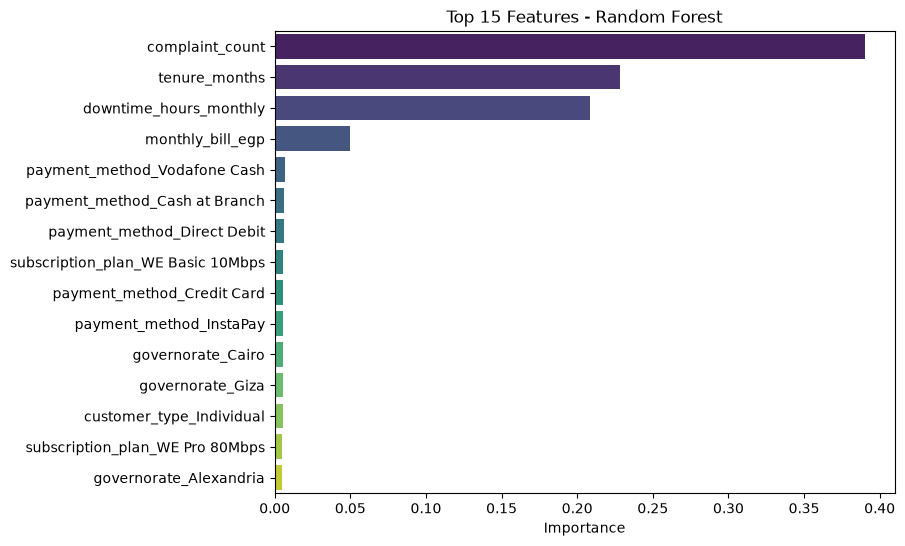

In [ ]:
names = [n.split('__', 1)[1] for n in final_model.named_steps['pre'].get_feature_names_out()]
imp = pd.Series(final_model.named_steps['model'].feature_importances_, index=names).sort_values(ascending=False).head(15)
plt.figure(figsize=(8, 6))
sns.barplot(x=imp.values, y=imp.index, hue=imp.index, palette='viridis', legend=False)
plt.title(f'Top 15 Features - {best_name}'); plt.xlabel('Importance'); plt.ylabel('')
plt.show()

### Save the artifacts

In [32]:
# [NEW] Save models/churn_model.joblib, models/metadata.json and models/metrics.json
MODELS_DIR = ROOT / 'models'
MODELS_DIR.mkdir(exist_ok=True)

oh = final_model.named_steps['pre'].named_transformers_['cat'].named_steps['oh']
metadata = {
    'model_name': best_name, 'target': TARGET, 'id_column_not_a_feature': 'customer_id',
    'features': {'numeric': num_cols, 'categorical': cat_cols}, 'feature_order': FEATURES,
    'categories': {c: [str(v) for v in cats] for c, cats in zip(cat_cols, oh.categories_)},
    'numeric_ranges': {c: {'min': float(X_train[c].min()), 'max': float(X_train[c].max())} for c in num_cols},
    'threshold': threshold, 'best_params': best_search.best_params_, 'random_state': SEED,
    'n_train': int(len(X_train)), 'n_test': int(len(X_test)), 'churn_rate_train': float(y_train.mean()),
    'trained_at_utc': datetime.now(timezone.utc).isoformat(timespec='seconds'),
    'library_versions': {'python': sys.version.split()[0], 'scikit-learn': sklearn.__version__,
                         'xgboost': xgboost.__version__, 'pandas': pd.__version__,
                         'numpy': np.__version__, 'joblib': joblib.__version__},
}
metrics = {
    'cv_comparison': cv_results,
    'search': {n: {'best_cv_pr_auc': float(s.best_score_), 'best_params': s.best_params_} for n, s in searches.items()},
    'chosen_model': best_name, 'threshold': threshold, 'cv_at_threshold': cv_at_threshold, 'test': test_metrics,
}

joblib.dump(final_model, MODELS_DIR / 'churn_model.joblib')
(MODELS_DIR / 'metadata.json').write_text(json.dumps(metadata, indent=2, default=to_native))
(MODELS_DIR / 'metrics.json').write_text(json.dumps(metrics, indent=2, default=to_native))
print('Saved to', MODELS_DIR.resolve())
print(json.dumps(metadata['library_versions'], indent=2))

Saved to C:\Users\dell\Desktop\Churn project\models
{
  "python": "3.14.6",
  "scikit-learn": "1.9.1",
  "xgboost": "3.4.1",
  "pandas": "3.0.5",
  "numpy": "2.5.3",
  "joblib": "1.6.0"
}


### Test the handoff in a fresh Python session

In [ ]:
HANDOFF_CODE = r'''
import json, sys, joblib, numpy as np, pandas as pd
meta = json.load(open(sys.argv[1])); model = joblib.load(sys.argv[2]); rows = json.loads(sys.argv[3])
num, cat = meta['features']['numeric'], meta['features']['categorical']
def frame(rec):  # one raw row -> DataFrame with raw column names (None -> NaN)
    df = pd.DataFrame([{c: rec.get(c) for c in num + cat}])
    for c in num: df[c] = pd.to_numeric(df[c], errors='coerce')
    for c in cat: df[c] = df[c].astype(object).where(df[c].notna(), np.nan)
    return df
for label, rec in rows.items():
    p = model.predict_proba(frame(rec))
    assert p.shape == (1, 2), p.shape
    prob = float(p[0, 1]); assert 0.0 <= prob <= 1.0
    print(f'  {label:<18} churn_probability={prob:.4f}  will_churn={prob >= meta["threshold"]}')
print('HANDOFF OK')
'''
typical = {k: (None if pd.isna(v) else v) for k, v in X_test.iloc[0].to_dict().items()}
rows = {
    'typical row': typical,
    'missing values': dict(typical, tenure_months=None, payment_method=None, downtime_hours_monthly=None),
    'unseen category': dict(typical, governorate='Atlantis'),
}
res = subprocess.run([sys.executable, '-I', '-c', HANDOFF_CODE, str(MODELS_DIR / 'metadata.json'),
                      str(MODELS_DIR / 'churn_model.joblib'), json.dumps(rows, default=to_native)],
                     capture_output=True, text=True)
print(res.stdout)
if res.returncode != 0:
    print(res.stderr)
    raise RuntimeError('Handoff test FAILED: the saved model does not work in a fresh session')

  typical row        churn_probability=0.6000  will_churn=True
  missing values     churn_probability=0.2850  will_churn=False
  unseen category    churn_probability=0.8350  will_churn=True
HANDOFF OK

